# Exploratory Data Analysis

### Step 0: Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("data/weather_data.csv")
df

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2025,67,S
1,2,36.0,118.0,8.0,72,5,2,2025,72,C
2,3,12.0,149.0,12.6,74,5,3,2025,74,PS
3,4,18.0,313.0,11.5,62,5,4,2025,62,S
4,5,NaN,NaN,14.3,56,5,5,2025,56,S
...,...,...,...,...,...,...,...,...,...,...
156,155,30.0,193.0,6.9,70,9,26,2025,70,PS
157,156,NaN,145.0,13.2,77,9,27,2025,77,S
158,157,14.0,191.0,14.3,75,9,28,2025,75,S
159,158,18.0,131.0,8.0,76,9,29,2025,76,C


### Step 1: Basic Data Understanding

In [6]:
df.shape

(161, 10)

In [7]:
df.head(12)

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2025,67,S
1,2,36.0,118.0,8.0,72,5,2,2025,72,C
2,3,12.0,149.0,12.6,74,5,3,2025,74,PS
3,4,18.0,313.0,11.5,62,5,4,2025,62,S
4,5,NaN,NaN,14.3,56,5,5,2025,56,S
5,6,28.0,NaN,14.9,66,5,6,2025,66,C
6,7,23.0,299.0,8.6,65,5,7,2025,65,PS
7,8,19.0,99.0,13.8,59,5,8,2025,59,C
8,9,8.0,19.0,20.1,61,5,9,2025,61,PS
9,10,NaN,194.0,8.6,69,5,10,2025,69,S


In [8]:
df.tail(6)

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
155,154,41.0,190.0,7.4,67,5,1,2025,67,C
156,155,30.0,193.0,6.9,70,9,26,2025,70,PS
157,156,NaN,145.0,13.2,77,9,27,2025,77,S
158,157,14.0,191.0,14.3,75,9,28,2025,75,S
159,158,18.0,131.0,8.0,76,9,29,2025,76,C
160,158,18.0,131.0,8.0,76,9,29,2025,76,C


In [9]:
df.dtypes

Unnamed: 0      int64
Ozone         float64
Solar.R       float64
Wind          float64
Temp C            str
Month             str
Day             int64
Year            int64
Temp            int64
Weather           str
dtype: object

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  161 non-null    int64  
 1   Ozone       123 non-null    float64
 2   Solar.R     154 non-null    float64
 3   Wind        161 non-null    float64
 4   Temp C      161 non-null    str    
 5   Month       161 non-null    str    
 6   Day         161 non-null    int64  
 7   Year        161 non-null    int64  
 8   Temp        161 non-null    int64  
 9   Weather     158 non-null    str    
dtypes: float64(3), int64(4), str(3)
memory usage: 12.7 KB


In [11]:
df.describe()

,Unnamed: 0,Ozone,Solar.R,Wind,Day,Year,Temp
count,161.000000,123.000000,154.000000,161.000000,161.000000,161.0,161.000000
mean,80.391304,41.837398,185.642857,9.903106,15.950311,2025.0,77.739130
std,46.121738,32.674343,88.237623,3.503274,9.066285,0.0,9.397155
min,1.000000,1.000000,7.000000,1.700000,1.000000,2025.0,56.000000
25%,41.000000,18.000000,121.750000,7.400000,8.000000,2025.0,72.000000
50%,80.000000,31.000000,195.500000,9.700000,16.000000,2025.0,78.000000
75%,120.000000,62.000000,257.500000,11.500000,24.000000,2025.0,84.000000
max,158.000000,168.000000,334.000000,20.700000,31.000000,2025.0,97.000000


In [12]:
df.describe(include="str")

,Temp C,Month,Weather
count,161,161,158
unique,41,6,3
top,81,9,S
freq,11,35,59


### Step 2: Data Preparation

In [13]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
156    False
157    False
158    False
159    False
160     True
Length: 161, dtype: bool

In [14]:
df.loc[df.duplicated()]

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
84,70,97.0,272.0,5.7,92,7,9,2025,92,C
155,154,41.0,190.0,7.4,67,5,1,2025,67,C
160,158,18.0,131.0,8.0,76,9,29,2025,76,C


In [16]:
df = df.drop_duplicates(ignore_index=True)
df

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2025,67,S
1,2,36.0,118.0,8.0,72,5,2,2025,72,C
2,3,12.0,149.0,12.6,74,5,3,2025,74,PS
3,4,18.0,313.0,11.5,62,5,4,2025,62,S
4,5,NaN,NaN,14.3,56,5,5,2025,56,S
...,...,...,...,...,...,...,...,...,...,...
153,154,41.0,190.0,7.4,67,5,1,2025,67,C
154,155,30.0,193.0,6.9,70,9,26,2025,70,PS
155,156,NaN,145.0,13.2,77,9,27,2025,77,S
156,157,14.0,191.0,14.3,75,9,28,2025,75,S


In [18]:
df.loc[df.duplicated()]

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather


In [19]:
df = df.drop(["Unnamed: 0", "Temp C"], axis=1)
df

,Ozone,Solar.R,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.0,7.4,5,1,2025,67,S
1,36.0,118.0,8.0,5,2,2025,72,C
2,12.0,149.0,12.6,5,3,2025,74,PS
3,18.0,313.0,11.5,5,4,2025,62,S
4,NaN,NaN,14.3,5,5,2025,56,S
...,...,...,...,...,...,...,...,...
153,41.0,190.0,7.4,5,1,2025,67,C
154,30.0,193.0,6.9,9,26,2025,70,PS
155,NaN,145.0,13.2,9,27,2025,77,S
156,14.0,191.0,14.3,9,28,2025,75,S


In [24]:
df = df.rename({"Solar.R": "Solar"}, axis=1)
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.0,7.4,5,1,2025,67,S
1,36.0,118.0,8.0,5,2,2025,72,C
2,12.0,149.0,12.6,5,3,2025,74,PS
3,18.0,313.0,11.5,5,4,2025,62,S
4,NaN,NaN,14.3,5,5,2025,56,S
...,...,...,...,...,...,...,...,...
153,41.0,190.0,7.4,5,1,2025,67,C
154,30.0,193.0,6.9,9,26,2025,70,PS
155,NaN,145.0,13.2,9,27,2025,77,S
156,14.0,191.0,14.3,9,28,2025,75,S


In [25]:
df.isna().sum()

Ozone      38
Solar       7
Wind        0
Month       0
Day         0
Year        0
Temp        0
Weather     3
dtype: int64

In [26]:
mean = df["Solar"].mean().round()
df["Solar"] = df["Solar"].fillna(mean)

In [29]:
df.isna().sum()

Ozone      38
Solar       0
Wind        0
Month       0
Day         0
Year        0
Temp        0
Weather     3
dtype: int64

In [32]:
df["Month"].unique()

<StringArray>
['5', 'May', '6', '7', '8', '9']
Length: 6, dtype: str

In [34]:
df["Month"].replace({"5": "May", "6": "June", "7": "July", "8": "August", "9": "September"}).unique()

<StringArray>
['May', 'June', 'July', 'August', 'September']
Length: 5, dtype: str

In [38]:
df["Month"] = df["Month"].replace({"May": "5", "June": "6", "July": "7", "August": "8", "September": "9"})
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.0,7.4,5,1,2025,67,S
1,36.0,118.0,8.0,5,2,2025,72,C
2,12.0,149.0,12.6,5,3,2025,74,PS
3,18.0,313.0,11.5,5,4,2025,62,S
4,NaN,185.0,14.3,5,5,2025,56,S
...,...,...,...,...,...,...,...,...
153,41.0,190.0,7.4,5,1,2025,67,C
154,30.0,193.0,6.9,9,26,2025,70,PS
155,NaN,145.0,13.2,9,27,2025,77,S
156,14.0,191.0,14.3,9,28,2025,75,S


In [40]:
df["Date"] = pd.to_datetime(df[["Year", "Month", "Day"]])
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather,Date
0,41.0,190.0,7.4,5,1,2025,67,S,2025-05-01
1,36.0,118.0,8.0,5,2,2025,72,C,2025-05-02
2,12.0,149.0,12.6,5,3,2025,74,PS,2025-05-03
3,18.0,313.0,11.5,5,4,2025,62,S,2025-05-04
4,NaN,185.0,14.3,5,5,2025,56,S,2025-05-05
...,...,...,...,...,...,...,...,...,...
153,41.0,190.0,7.4,5,1,2025,67,C,2025-05-01
154,30.0,193.0,6.9,9,26,2025,70,PS,2025-09-26
155,NaN,145.0,13.2,9,27,2025,77,S,2025-09-27
156,14.0,191.0,14.3,9,28,2025,75,S,2025-09-28


<Axes: >

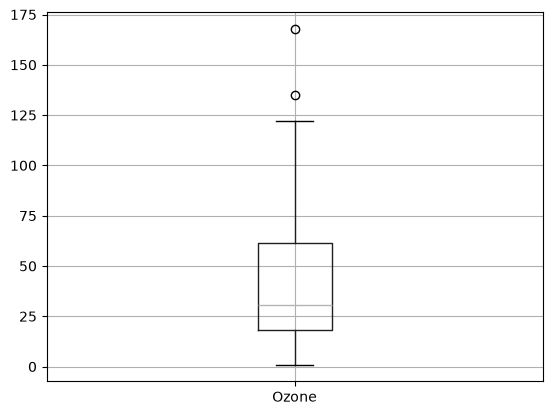

In [41]:
df.boxplot(column="Ozone")

In [42]:
df["Ozone"].describe()

count    120.000000
mean      41.583333
std       32.620709
min        1.000000
25%       18.000000
50%       30.500000
75%       61.500000
max      168.000000
Name: Ozone, dtype: float64

In [47]:
IQR = 61.500000 - 18.000000
max_limit = 61.500000 + IQR * 1.5
max_limit

126.75

In [51]:
df[df["Ozone"]>max_limit]

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather,Date
61,135.0,269.0,4.1,7,1,2025,84,S,2025-07-01
116,168.0,238.0,3.4,8,25,2025,81,PS,2025-08-25


### Step 3: Univariate Analysis (Feature Understanding)

In [55]:
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather,Date
0,41.0,190.0,7.4,5,1,2025,67,S,2025-05-01
1,36.0,118.0,8.0,5,2,2025,72,C,2025-05-02
2,12.0,149.0,12.6,5,3,2025,74,PS,2025-05-03
3,18.0,313.0,11.5,5,4,2025,62,S,2025-05-04
4,NaN,185.0,14.3,5,5,2025,56,S,2025-05-05
...,...,...,...,...,...,...,...,...,...
153,41.0,190.0,7.4,5,1,2025,67,C,2025-05-01
154,30.0,193.0,6.9,9,26,2025,70,PS,2025-09-26
155,NaN,145.0,13.2,9,27,2025,77,S,2025-09-27
156,14.0,191.0,14.3,9,28,2025,75,S,2025-09-28


In [58]:
df["Weather"] = df["Weather"].replace({"S": "Sunny", "C": "Cloudy", "PS": "Partialy Sunny"})
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather,Date
0,41.0,190.0,7.4,5,1,2025,67,Sunny,2025-05-01
1,36.0,118.0,8.0,5,2,2025,72,Cloudy,2025-05-02
2,12.0,149.0,12.6,5,3,2025,74,Partialy Sunny,2025-05-03
3,18.0,313.0,11.5,5,4,2025,62,Sunny,2025-05-04
4,NaN,185.0,14.3,5,5,2025,56,Sunny,2025-05-05
...,...,...,...,...,...,...,...,...,...
153,41.0,190.0,7.4,5,1,2025,67,Cloudy,2025-05-01
154,30.0,193.0,6.9,9,26,2025,70,Partialy Sunny,2025-09-26
155,NaN,145.0,13.2,9,27,2025,77,Sunny,2025-09-27
156,14.0,191.0,14.3,9,28,2025,75,Sunny,2025-09-28


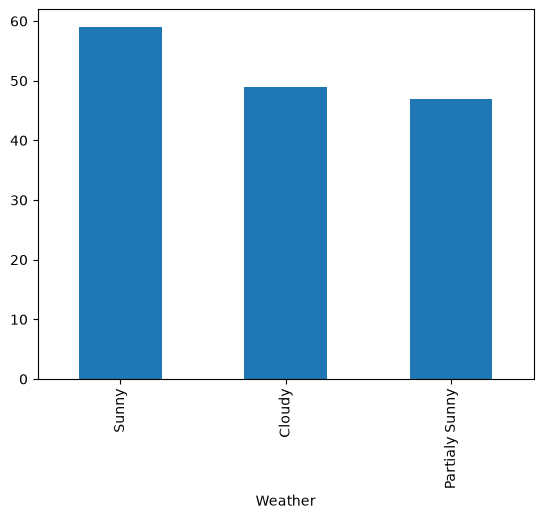

In [61]:
df["Weather"].value_counts().plot(kind="bar")
plt.show()

In [62]:
df.columns

Index(['Ozone', 'Solar', 'Wind', 'Month', 'Day', 'Year', 'Temp', 'Weather',
       'Date'],
      dtype='str')

In [63]:
df["Wind"]

0       7.4
1       8.0
2      12.6
3      11.5
4      14.3
       ... 
153     7.4
154     6.9
155    13.2
156    14.3
157     8.0
Name: Wind, Length: 158, dtype: float64

In [65]:
df.var(numeric_only=True)

Ozone    1064.110644
Solar    7520.824518
Wind       12.328955
Day        80.949004
Year        0.000000
Temp       87.944570
dtype: float64

In [66]:
df.skew(numeric_only=True)

Ozone    1.282000
Solar   -0.425459
Wind     0.349332
Day     -0.036407
Year     0.000000
Temp    -0.340108
dtype: float64

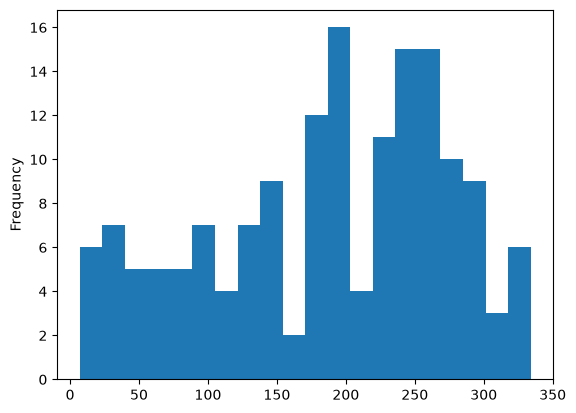

In [72]:
df["Solar"].plot(kind="hist", bins=20)
plt.show()

In [74]:
df["Wind"].plot(kind="kde")
plt.show()

ModuleNotFoundError: No module named 'scipy'

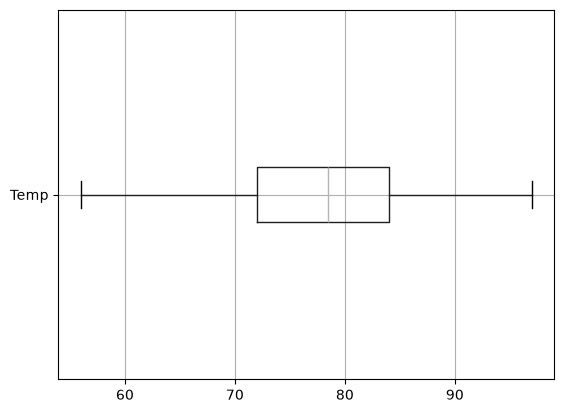

In [81]:
df.boxplot(column="Temp", vert=False)
plt.show()

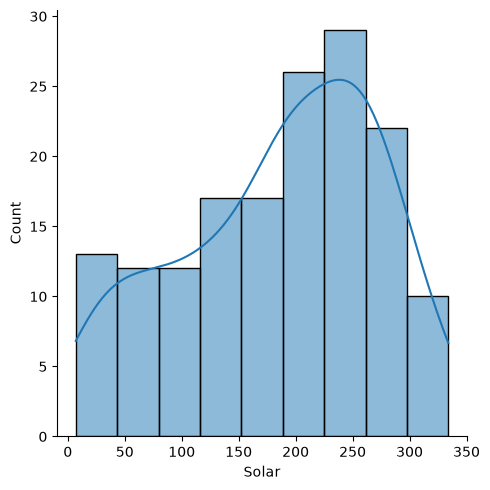

In [85]:
sns.displot(data=df, x='Solar', kind='hist', kde=True)
plt.show()